In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

In [2]:
iris = load_iris(as_frame=True)

df = iris.frame

df["species"] = df["target"].map(dict(enumerate(iris.target_names)))

print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target species  
0       0  setosa  
1       0  setosa  
2       0  setosa  
3       0  setosa  
4       0  setosa  


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nSpecies counts:")
print(df["species"].value_counts())

print("\nSummary statistics:")
print(df.describe())

Dataset shape: (150, 6)

Column names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target', 'species']

Species counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Summary statistics:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)      target  
count        150.000000  150.000000  
mean           1.199333    1.000000  
std            0.762238    0.81923

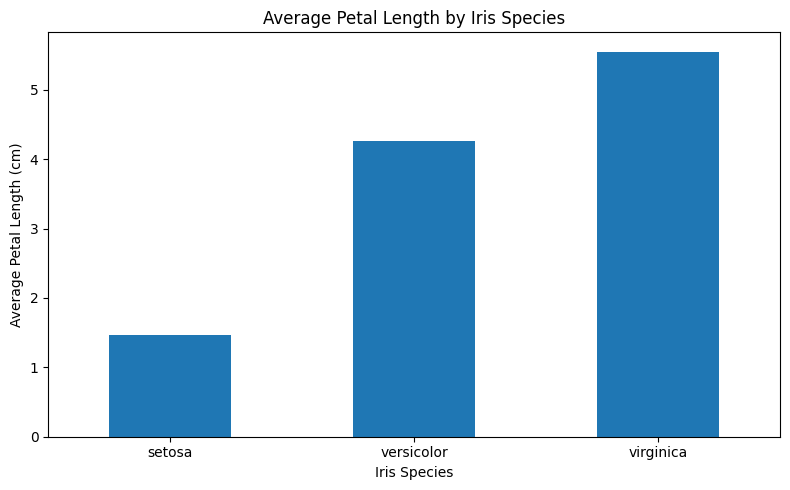

In [4]:
avg_petal_length = df.groupby("species")["petal length (cm)"].mean()

plt.figure(figsize=(8, 5))

avg_petal_length.plot(kind="bar")

plt.title("Average Petal Length by Iris Species")
plt.xlabel("Iris Species")
plt.ylabel("Average Petal Length (cm)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig("average_petal_length.png", dpi=300)
plt.show()

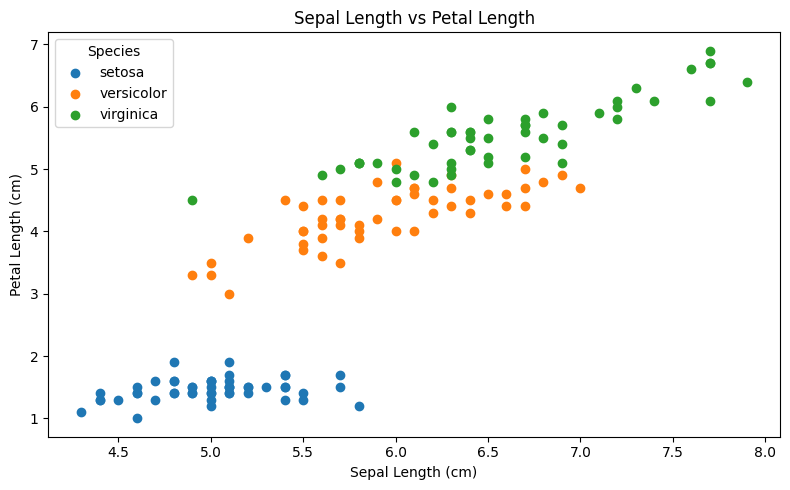

In [6]:
plt.figure(figsize=(8, 5))

for species in df["species"].unique():
    subset = df[df["species"] == species]

    plt.scatter(
        subset["sepal length (cm)"],
        subset["petal length (cm)"],
        label=species
    )

plt.title("Sepal Length vs Petal Length")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Length (cm)")
plt.legend(title="Species")

plt.tight_layout()
plt.savefig("sepal_vs_petal.png", dpi=300)
plt.show()

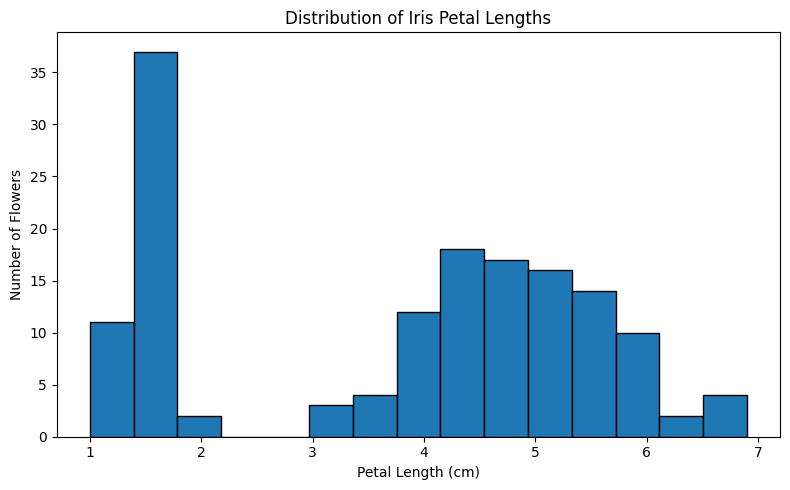

In [5]:
plt.figure(figsize=(8, 5))

plt.hist(df["petal length (cm)"],
    bins=15,
    edgecolor="black")

plt.title("Distribution of Iris Petal Lengths")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Number of Flowers")

plt.tight_layout()
plt.savefig("petal_length_distribution.png", dpi=300)
plt.show()